# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [2]:
!pip install nltk numpy matplotlib

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ------------------------ --------------- 1.0/1.7 MB 2.8 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 2.9 MB/s  0:00:00

   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------- ----------------------------- 1/4 [regex]
   ---------- ----------------------------- 1/4 [regex]
   -------------------- ------------------- 2/4 [defusedxml]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ---------------------------


[notice] A new release of pip is available: 26.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import nltk
import re
import time
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

In [4]:
nltk.download('gutenberg')
from nltk.corpus import gutenberg

[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\gutenberg.zip.


In [5]:
fileids = gutenberg.fileids()
num_docs = len(fileids)
print(f"Número de documentos en el corpus pequeño: {num_docs}")

docs_raw = {}
doc_sizes = {}
for fid in fileids:
    raw_text = gutenberg.raw(fid)
    docs_raw[fid] = raw_text
    doc_sizes[fid] = len(raw_text)

Número de documentos en el corpus pequeño: 18


In [6]:
for fid, size in list(doc_sizes.items()):
    print(f" - {fid}: {size} caracteres")

 - austen-emma.txt: 887071 caracteres
 - austen-persuasion.txt: 466292 caracteres
 - austen-sense.txt: 673022 caracteres
 - bible-kjv.txt: 4332554 caracteres
 - blake-poems.txt: 38153 caracteres
 - bryant-stories.txt: 249439 caracteres
 - burgess-busterbrown.txt: 84663 caracteres
 - carroll-alice.txt: 144395 caracteres
 - chesterton-ball.txt: 457450 caracteres
 - chesterton-brown.txt: 406629 caracteres
 - chesterton-thursday.txt: 320525 caracteres
 - edgeworth-parents.txt: 935158 caracteres
 - melville-moby_dick.txt: 1242990 caracteres
 - milton-paradise.txt: 468220 caracteres
 - shakespeare-caesar.txt: 112310 caracteres
 - shakespeare-hamlet.txt: 162881 caracteres
 - shakespeare-macbeth.txt: 100351 caracteres
 - whitman-leaves.txt: 711215 caracteres


In [7]:
def preprocess(text):
    text = text.lower()
    tokens = re.findall(r'\b[a-záéíóúñü]+\b', text)
    return tokens

In [8]:
corpus_tokens = {}
for fid in fileids:
    corpus_tokens[fid] = preprocess(docs_raw[fid])

In [9]:
print("\nEjemplo de preprocesamiento en el primer documento:")
print(f"Documento: {fileids[0]} | Tokens totales: {len(corpus_tokens[fileids[0]])}")
print(f"Primeros 15 tokens: {corpus_tokens[fileids[0]][:15]}")


Ejemplo de preprocesamiento en el primer documento:
Documento: austen-emma.txt | Tokens totales: 161600
Primeros 15 tokens: ['emma', 'by', 'jane', 'austen', 'volume', 'i', 'chapter', 'i', 'emma', 'woodhouse', 'handsome', 'clever', 'and', 'rich', 'with']


**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [10]:
def sequential_search(query_term, corpus):
    matching_docs = []
    normalized_query = query_term.lower()
    
    # Primer bucle: recorre los documentos
    for doc_id, tokens in corpus.items():
        found = False
        # Segundo bucle: recorre los tokens de cada documento
        for token in tokens:
            if token == normalized_query:
                found = True
                break # Encontrado en el documento, pasamos al siguiente doc
        if found:
            matching_docs.append(doc_id)
            
    return matching_docs

In [11]:
termino_frecuente = "the"
termino_poco_frecuente = "monster"
termino_inexistente = "xyzzyabc"

In [12]:
print(f"Búsqueda secuencial para '{termino_frecuente}':", sequential_search(termino_frecuente, corpus_tokens))
print(f"Búsqueda secuencial para '{termino_poco_frecuente}':", sequential_search(termino_poco_frecuente, corpus_tokens))
print(f"Búsqueda secuencial para '{termino_inexistente}':", sequential_search(termino_inexistente, corpus_tokens))

Búsqueda secuencial para 'the': ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
Búsqueda secuencial para 'monster': ['bryant-stories.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'melville-moby_dick.txt', 'milton-paradise.txt']
Búsqueda secuencial para 'xyzzyabc': []


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [13]:
def measure_sequential_time(query_term, corpus, repetitions=30):
    _ = sequential_search(query_term, corpus)
    
    times = []
    for _ in range(repetitions):
        start_time = time.perf_counter_ns()
        _ = sequential_search(query_term, corpus)
        end_time = time.perf_counter_ns()
        times.append(end_time - start_time)
        
    mean_time_ns = np.mean(times)
    mean_time_ms = mean_time_ns / 1_000_000.0 # Convertir nanosegundos a milisegundos
    return mean_time_ms

In [18]:
queries = ["the", "and", "whale", "monster", "tangamandapio"]

In [19]:
print("Tiempos de ejecución medios (Búsqueda Secuencial - 30 ejecuciones):")
for q in queries:
    t_mean = measure_sequential_time(q, corpus_tokens)
    print(f" - Consulta '{q}': {t_mean:.4f} ms")

Tiempos de ejecución medios (Búsqueda Secuencial - 30 ejecuciones):
 - Consulta 'the': 0.0046 ms
 - Consulta 'and': 0.0073 ms
 - Consulta 'whale': 20.8721 ms
 - Consulta 'monster': 24.7948 ms
 - Consulta 'tangamandapio': 31.5653 ms


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [22]:
class InvertedIndex:
    def __init__(self, corpus):
        self.index = defaultdict(set)
        self.build_index(corpus)
        
    def build_index(self, corpus):
        for doc_id, tokens in corpus.items():
            for token in tokens:
                self.index[token].add(doc_id)
                
    def get_postings(self, term):
        return sorted(list(self.index.get(term.lower(), set())))
    
    def document_frequency(self, term):
        return len(self.index.get(term.lower(), set()))
    
    def search_term(self, term):
        return self.get_postings(term)
    
    def search_boolean_and(self, term1, term2):
        set1 = self.index.get(term1.lower(), set())
        set2 = self.index.get(term2.lower(), set())
        return sorted(list(set1.intersection(set2)))
    
    def search_boolean_or(self, term1, term2):
        set1 = self.index.get(term1.lower(), set())
        set2 = self.index.get(term2.lower(), set())
        return sorted(list(set1.union(set2)))
    
    def search_boolean_not(self, term1, term2, all_docs):
        # Documentos que contienen term1 pero NO term2
        set1 = self.index.get(term1.lower(), set())
        set2 = self.index.get(term2.lower(), set())
        return sorted(list(set1.difference(set2)))

In [23]:
inv_index = InvertedIndex(corpus_tokens)

In [25]:
sample_terms = ["whale", "emma", "moby", "god", "tangamandapio"]
print("Frecuencia Documental (DF) de términos:")
for t in sample_terms:
    df = inv_index.document_frequency(t)
    print(f" - DF('{t}'): {df} documentos")

Frecuencia Documental (DF) de términos:
 - DF('whale'): 6 documentos
 - DF('emma'): 2 documentos
 - DF('moby'): 1 documentos
 - DF('god'): 16 documentos
 - DF('tangamandapio'): 0 documentos


In [26]:
all_doc_ids = list(corpus_tokens.keys())
print("\nPrueba de consulta AND ('whale' AND 'ahab'):", inv_index.search_boolean_and("whale", "ahab"))
print("Prueba de consulta OR ('emma' OR 'sense'):", inv_index.search_boolean_or("emma", "sense"))
print("Prueba de consulta NOT ('whale' NOT 'ahab'):", inv_index.search_boolean_not("whale", "ahab", all_doc_ids))


Prueba de consulta AND ('whale' AND 'ahab'): ['bible-kjv.txt', 'melville-moby_dick.txt']
Prueba de consulta OR ('emma' OR 'sense'): ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
Prueba de consulta NOT ('whale' NOT 'ahab'): ['bryant-stories.txt', 'chesterton-ball.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [27]:
def measure_index_time(query_term, index_obj, repetitions=30):
    _ = index_obj.search_term(query_term)
    times = []
    for _ in range(repetitions):
        start = time.perf_counter_ns()
        _ = index_obj.search_term(query_term)
        end = time.perf_counter_ns()
        times.append(end - start)
    return (np.mean(times)) / 1_000_000.0

In [29]:
print("Comparación de Resultados y Tiempos (Secuencial vs Índice Invertido):")
test_queries = ["whale", "emma", "ahab", "ring", "tangamandapio"]

print(f"{'Consulta':<12} | {'Secuencial (ms)':<18} | {'Índice (ms)':<15} | {'Resultados Iguales?'}")
print("-" * 65)

for q in test_queries:
    res_seq = sorted(sequential_search(q, corpus_tokens))
    res_inv = sorted(inv_index.search_term(q))
    
    t_seq = measure_sequential_time(q, corpus_tokens)
    t_inv = measure_index_time(q, inv_index)
    
    match = (res_seq == res_inv)
    print(f"{q:<12} | {t_seq:<18.4f} | {t_inv:<15.4f} | {str(match)}")

Comparación de Resultados y Tiempos (Secuencial vs Índice Invertido):
Consulta     | Secuencial (ms)    | Índice (ms)     | Resultados Iguales?
-----------------------------------------------------------------
whale        | 19.6164            | 0.0006          | True
emma         | 32.8860            | 0.0005          | True
ahab         | 24.9813            | 0.0008          | True
ring         | 7.5443             | 0.0007          | True
tangamandapio | 31.0476            | 0.0004          | True


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [2]:
import os
import urllib.request
import tarfile
import zipfile

url = "https://www.gutenberg.org/cache/epub/feeds/txt-files.tar.zip"
zip_path = "txt-files.tar.zip"
extracted_dir = "gutenberg_txt_files"

if not os.path.exists(zip_path):
    print("Descargando el archivo comprimido de Gutenberg (esto puede tomar varios minutos)...")
    urllib.request.urlretrieve(url, zip_path)
    print("Descarga completada.")

if not os.path.exists(extracted_dir):
    os.makedirs(extracted_dir, exist_ok=True)
    print("Descomprimiendo archivos...")
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(extracted_dir)
    # Extraer el tar interno si existe
    tar_files = [f for f in os.listdir(extracted_dir) if f.endswith('.tar') or f.endswith('.tar.gz')]
    for tf in tar_files:
        tar_filepath = os.path.join(extracted_dir, tf)
        with tarfile.open(tar_filepath, 'r') as tar:
            tar.extractall(extracted_dir)
    print("Descompresión finalizada.")

large_corpus_docs = {}

for root, dirs, files in os.walk(extracted_dir):
    for file in files:
        if file.endswith('.txt'):
            file_path = os.path.join(root, file)
            
            doc_id = os.path.relpath(file_path, extracted_dir)
            try:
                with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
                    content = f.read()
                    # Filtrar archivos vacíos o redundantes de control si los hubiera
                    if len(content.strip()) > 100: 
                        large_corpus_docs[doc_id] = content
            except Exception as e:
                pass



In [3]:
print(f"Total de documentos válidos identificados en el corpus grande: {len(large_corpus_docs)}")

Total de documentos válidos identificados en el corpus grande: 78145


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [6]:
import re
from collections import defaultdict

# 1. Definir preprocesamiento si no está en memoria
def preprocess(text):
    text = text.lower()
    tokens = re.findall(r'\b[a-záéíóúñü]+\b', text)
    return tokens

# 2. Definir búsqueda secuencial si no está en memoria
def sequential_search(query_term, corpus):
    matching_docs = []
    normalized_query = query_term.lower()
    for doc_id, tokens in corpus.items():
        found = False
        for token in tokens:
            if token == normalized_query:
                found = True
                break
        if found:
            matching_docs.append(doc_id)
    return matching_docs

# 3. Definir la clase InvertedIndex si no está en memoria
class InvertedIndex:
    def __init__(self, corpus):
        self.index = defaultdict(set)
        self.build_index(corpus)
        
    def build_index(self, corpus):
        for doc_id, tokens in corpus.items():
            for token in tokens:
                self.index[token].add(doc_id)
                
    def get_postings(self, term):
        return sorted(list(self.index.get(term.lower(), set())))
    
    def search_term(self, term):
        return self.get_postings(term)

# Selección y procesamiento del subconjunto
subset_keys = list(large_corpus_docs.keys())[:100]
large_corpus_subset = {k: large_corpus_docs[k] for k in subset_keys}

print(f"Procesando tokens para el subconjunto de {len(large_corpus_subset)} documentos...")
large_corpus_tokens = {doc_id: preprocess(text) for doc_id, text in large_corpus_subset.items()}

# Ahora ya cuenta con InvertedIndex definido
large_inv_index = InvertedIndex(large_corpus_tokens)

consulta_prueba = "the"
print(f"Validando consulta '{consulta_prueba}' en subconjunto grande:")
res_s = sorted(sequential_search(consulta_prueba, large_corpus_tokens))
res_i = sorted(large_inv_index.search_term(consulta_prueba))
print(f" - Coincidencia exacta de resultados: {res_s == res_i}")
print(f" - Número de documentos recuperados: {len(res_s)}")

Procesando tokens para el subconjunto de 100 documentos...
Validando consulta 'the' en subconjunto grande:
 - Coincidencia exacta de resultados: True
 - Número de documentos recuperados: 100


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

Ejecutando pruebas de escalabilidad...
 n =   50 documentos | Tokens:  4077896 | Secuencial:   5.8437 ms | Índice Invertido:   0.0016 ms
 n =  100 documentos | Tokens:  7286560 | Secuencial:  14.8189 ms | Índice Invertido:   0.0038 ms
 n =  250 documentos | Tokens: 18939254 | Secuencial:  39.9835 ms | Índice Invertido:   0.0099 ms
 n =  500 documentos | Tokens: 35851949 | Secuencial:  93.3785 ms | Índice Invertido:   0.0577 ms
 n = 1000 documentos | Tokens: 71487369 | Secuencial: 254.6526 ms | Índice Invertido:   0.0696 ms


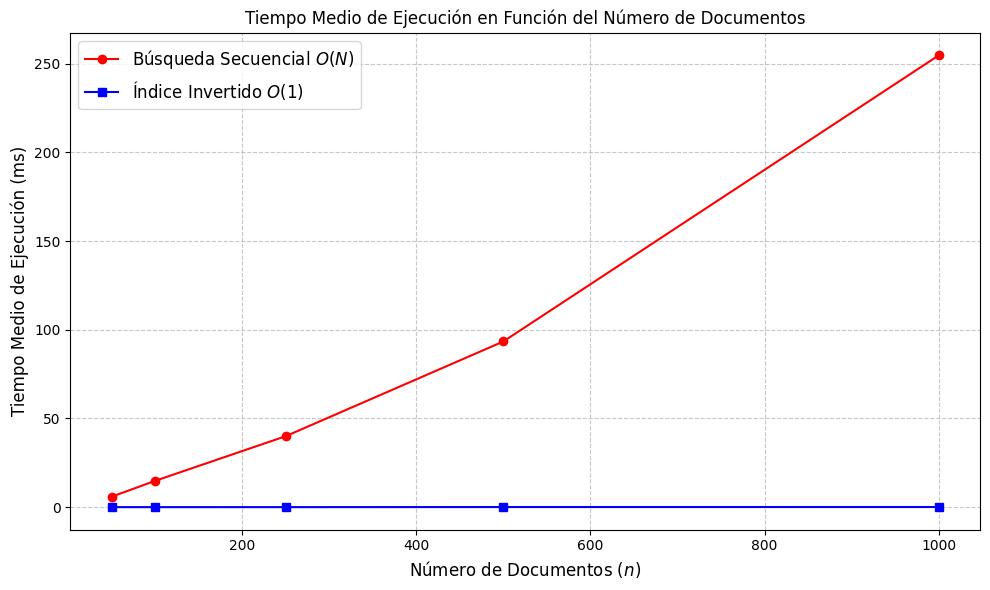

In [10]:
import time
import numpy as np
import matplotlib.pyplot as plt

def measure_sequential_time(query_term, corpus, repetitions=30):
    _ = sequential_search(query_term, corpus)
    times = []
    for _ in range(repetitions):
        start_time = time.perf_counter_ns()
        _ = sequential_search(query_term, corpus)
        end_time = time.perf_counter_ns()
        times.append(end_time - start_time)
    return np.mean(times) / 1_000_000.0

def measure_index_time(query_term, index_obj, repetitions=30):
    _ = index_obj.search_term(query_term)
    times = []
    for _ in range(repetitions):
        start = time.perf_counter_ns()
        _ = index_obj.search_term(query_term)
        end = time.perf_counter_ns()
        times.append(end - start)
    return np.mean(times) / 1_000_000.0

tamanios = [50, 100, 250, 500, 1000]
tamanios = [n for n in tamanios if n <= len(large_corpus_docs)]

query_benchmark = "book"

tiempos_secuencial = []
tiempos_indice = []
tokens_totales_lista = []

all_keys = list(large_corpus_docs.keys())

print("Ejecutando pruebas de escalabilidad...")
for n in tamanios:
    sub_keys = all_keys[:n]
    sub_corpus_raw = {k: large_corpus_docs[k] for k in sub_keys}
    
    sub_tokens = {k: preprocess(text) for k, text in sub_corpus_raw.items()}
    total_tokens = sum(len(toks) for toks in sub_tokens.values())
    tokens_totales_lista.append(total_tokens)
    
    t_seq = measure_sequential_time(query_benchmark, sub_tokens, repetitions=30)
    tiempos_secuencial.append(t_seq)
    
    sub_index = InvertedIndex(sub_tokens)
    t_ind = measure_index_time(query_benchmark, sub_index, repetitions=30)
    tiempos_indice.append(t_ind)
    
    print(f" n = {n:4d} documentos | Tokens: {total_tokens:8d} | Secuencial: {t_seq:8.4f} ms | Índice Invertido: {t_ind:8.4f} ms")

plt.figure(figsize=(10, 6))
plt.plot(tamanios, tiempos_secuencial, marker='o', linestyle='-', color='red', label='Búsqueda Secuencial $O(N)$')
plt.plot(tamanios, tiempos_indice, marker='s', linestyle='-', color='blue', label='Índice Invertido $O(1)$')
plt.title('Tiempo Medio de Ejecución en Función del Número de Documentos')
plt.xlabel('Número de Documentos ($n$)', fontsize=12)
plt.ylabel('Tiempo Medio de Ejecución (ms)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

--- RESULTADOS DEL AJUSTE LINEAL ---
Búsqueda Secuencial -> t(n) = 0.261716 * n + -17.7165  (R² = 0.9830)
Índice Invertido    -> t(n) = 0.000078 * n + -0.0012  (R² = 0.8748)


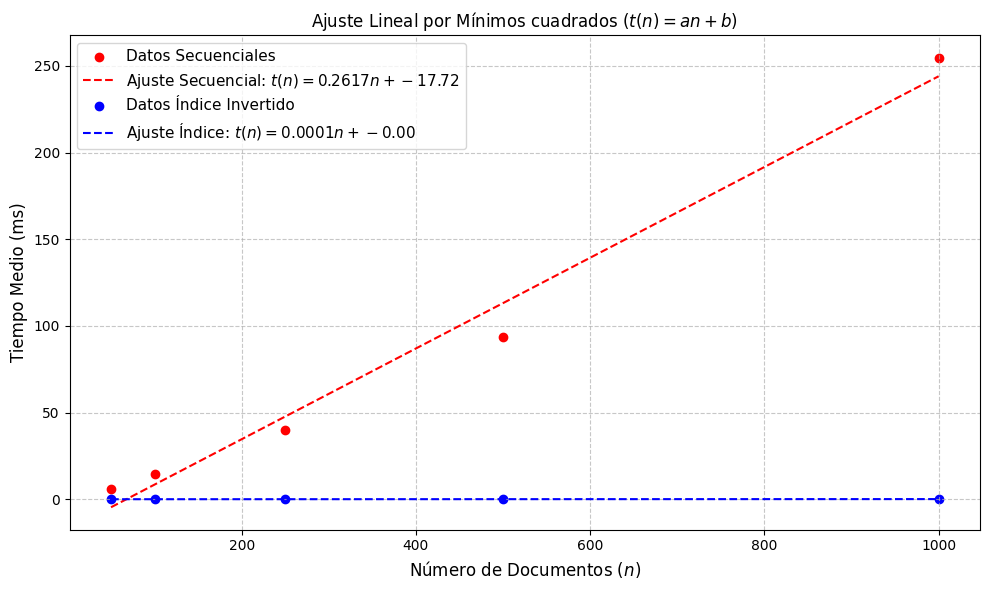

In [12]:
n_array = np.array(tamanios, dtype=float)

a_seq, b_seq = np.polyfit(n_array, tiempos_secuencial, 1)
y_pred_seq = a_seq * n_array + b_seq

ss_res_seq = np.sum((np.array(tiempos_secuencial) - y_pred_seq) ** 2)
ss_tot_seq = np.sum((np.array(tiempos_secuencial) - np.mean(tiempos_secuencial)) ** 2)
r2_seq = 1 - (ss_res_seq / ss_tot_seq) if ss_tot_seq != 0 else 1.0

a_ind, b_ind = np.polyfit(n_array, tiempos_indice, 1)
y_pred_ind = a_ind * n_array + b_ind

ss_res_ind = np.sum((np.array(tiempos_indice) - y_pred_ind) ** 2)
ss_tot_ind = np.sum((np.array(tiempos_indice) - np.mean(tiempos_indice)) ** 2)
r2_ind = 1 - (ss_res_ind / ss_tot_ind) if ss_tot_ind != 0 else 1.0

print("--- RESULTADOS DEL AJUSTE LINEAL ---")
print(f"Búsqueda Secuencial -> t(n) = {a_seq:.6f} * n + {b_seq:.4f}  (R² = {r2_seq:.4f})")
print(f"Índice Invertido    -> t(n) = {a_ind:.6f} * n + {b_ind:.4f}  (R² = {r2_ind:.4f})")

plt.figure(figsize=(10, 6))
plt.scatter(tamanios, tiempos_secuencial, color='red', label='Datos Secuenciales')
plt.plot(tamanios, y_pred_seq, color='red', linestyle='--', label=f'Ajuste Secuencial: $t(n)={a_seq:.4f}n+{b_seq:.2f}$')

plt.scatter(tamanios, tiempos_indice, color='blue', label='Datos Índice Invertido')
plt.plot(tamanios, y_pred_ind, color='blue', linestyle='--', label=f'Ajuste Índice: $t(n)={a_ind:.4f}n+{b_ind:.2f}$')

plt.title('Ajuste Lineal por Mínimos cuadrados ($t(n) = an + b$)')
plt.xlabel('Número de Documentos ($n$)', fontsize=12)
plt.ylabel('Tiempo Medio (ms)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()
